<a href="https://colab.research.google.com/github/Taheri1400/deep-learning-projects/blob/main/example_simple_unet_part_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1 align=center style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
قطعه‌بندی معنایی اشکال هندسی با UNet
</font>
</h1>

<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazir" size=3>
در این پروژه، هدف ما آموزش یک مدل یادگیری عمیق (UNet) برای <b>قطعه‌بندی معنایی</b> تصاویر است؛ یعنی مدل باید برای هر پیکسل تصویر تشخیص دهد که متعلق به کدام کلاس (پس‌زمینه، دایره، مستطیل، مثلث) است. این پروژه به صورت مرحله‌به‌مرحله و با توضیحات ساده و علمی پیاده‌سازی شده تا برای افراد تازه‌وارد نیز قابل فهم باشد.
</font>
</p>



In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from tqdm import trange
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from tensorflow.keras.metrics import MeanIoU

In [2]:
# تنظیم فونت فارسی برای matplotlib
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Tahoma'
plt.rcParams['font.size'] = 12
plt.rcParams['axes.unicode_minus'] = False  # نمایش صحیح علامت منفی

In [3]:
# اگر arabic_reshaper و python-bidi نصب نیستند:
!pip install arabic-reshaper python-bidi
import arabic_reshaper
from bidi.algorithm import get_display

def fa_text(text):
    return get_display(arabic_reshaper.reshape(text))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 295.7/295.7 kB 2.1 MB/s eta 0:00:00


<h4 dir=rtl align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazirmatn" color="#0099cc">
آماده‌سازی و فراخوانی داده‌های واقعی
</font>
</h4>
<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazirmatn" size=3>
در این بخش، داده‌های واقعی مورد استفاده برای آموزش مدل را بارگذاری می‌کنیم. این داده‌ها شامل تصاویر ورودی (مثلاً تصاویر اشکال هندسی) و ماسک‌های متناظر با آن‌ها هستند که برای هر پیکسل، کلاس مربوطه (پس‌زمینه، دایره، مستطیل، مثلث) را مشخص می‌کند.
<br><b>ساختار داده‌ها:</b>
<ul>
<li>پوشه <code>output/train_images</code>: شامل تصاویر ورودی با فرمت PNG است.</li>
<li>پوشه <code>output/train_masks</code>: شامل ماسک‌های برچسب‌گذاری‌شده با فرمت PNG است که هر پیکسل مقدار عددی کلاس را دارد.</li>
</ul>
در این سلول، ابتدا نام فایل‌های تصاویر و ماسک‌ها را می‌خوانیم و سپس با استفاده از حلقه، هر تصویر و ماسک متناظر را بارگذاری می‌کنیم. اگر ماسک به صورت RGB ذخیره شده باشد، با استفاده از <code>argmax</code> آن را به برچسب عددی تبدیل می‌کنیم. در نهایت، داده‌ها را به آرایه‌های numpy تبدیل می‌کنیم تا برای آموزش مدل آماده باشند.
<br>همچنین چند نمونه از تصاویر و ماسک‌ها را برای بررسی صحت بارگذاری نمایش می‌دهیم.
</font>
</p>

In [4]:
# مسیر پوشه تصاویر و ماسک‌ها (data/train/images و data/train/masks)
images_dir = './train/images'
masks_dir = './train/masks'

# لیست نام فایل‌ها
image_files = sorted([f for f in os.listdir(images_dir) if f.endswith('.png')])
mask_files = sorted([f for f in os.listdir(masks_dir) if f.endswith('.png')])

import cv2  # اگر opencv نصب نیست: !pip install opencv-python
IMG_SIZE = 128  # سایز هدف تصاویر و ماسک‌ها

# بارگذاری همه تصاویر و ماسک‌ها در آرایه numpy
X = []
Y = []
for img_name, mask_name in zip(image_files, mask_files):
    img_path = os.path.join(images_dir, img_name)
    mask_path = os.path.join(masks_dir, mask_name)
    img = plt.imread(img_path)
    mask = plt.imread(mask_path)
    # اگر ماسک RGB است، فقط کانال اول را بردار (یا argmax بگیر)
    if mask.ndim == 3:
        mask = np.argmax(mask, axis=-1)
    # تغییر اندازه تصویر و ماسک به سایز ثابت
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    mask = cv2.resize(mask, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST)
    # تبدیل تصویر به تک‌کاناله (در صورت نیاز)
    if img.ndim == 3:
        img = img[..., 0]
    img = img[..., np.newaxis]  # تبدیل به (128,128,1)
    X.append(img)
    Y.append(mask)

X = np.array(X).astype(np.float32)
Y = np.array(Y).astype(np.uint8)

print('شکل داده‌های ورودی: ', X.shape)
print('شکل ماسک‌ها: ', Y.shape)

شکل داده‌های ورودی:  (200, 128, 128, 1)
شکل ماسک‌ها:  (200, 128, 128)


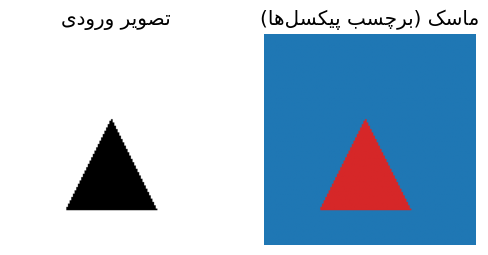

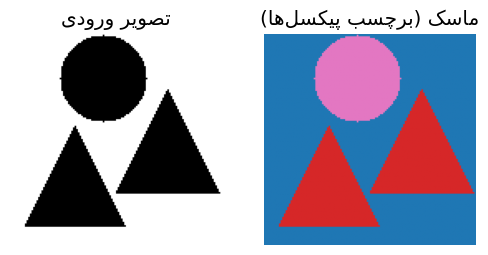

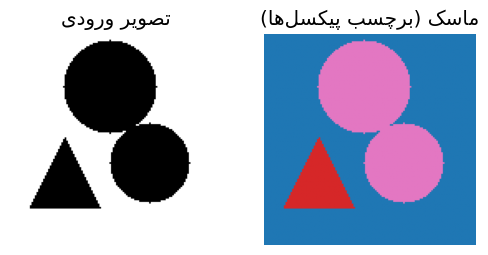

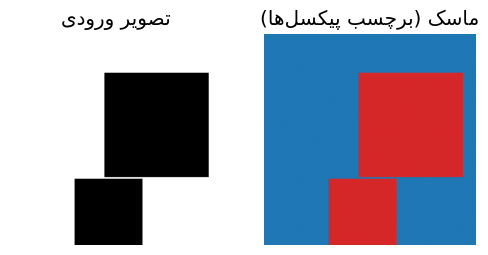

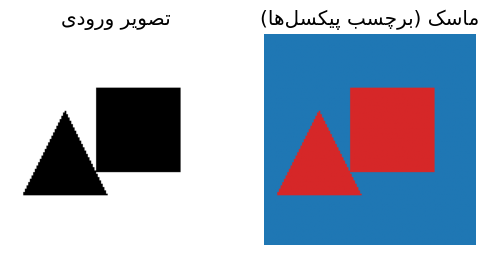

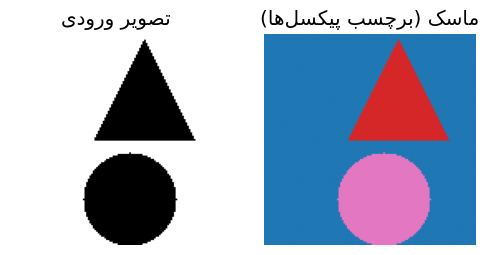

In [5]:
import random

random_index = []

while len(random_index) < 6:
    temp = random.randint(0, X.shape[0]- 1)
    if temp not in random_index:
        random_index.append(temp)

# نمایش چند نمونه تصویر و ماسک
for i in random_index:
    plt.figure(figsize=(6,3))
    plt.subplot(1,2,1)
    plt.imshow(X[i].squeeze(), cmap='gray')
    plt.title(fa_text('تصویر ورودی'))
    plt.axis('off')
    plt.subplot(1,2,2)
    plt.imshow(Y[i], cmap='tab10', vmin=0, vmax=3)
    plt.title(fa_text('ماسک (برچسب پیکسل‌ها)'))
    plt.axis('off')
    plt.show()

<h4 dir=rtl align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazirmatn" color="#0099cc">
طراحی مدل UNet
</font>
</h4>
<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazirmatn" size=3>
در این بخش، مدل UNet را به صورت گام‌به‌گام و بدون استفاده از توابع آماده می‌سازیم. UNet یک معماری معروف برای قطعه‌بندی تصاویر است که از مسیر پایین‌رو (encoder) برای استخراج ویژگی‌ها و مسیر بالا‌رو (decoder) برای بازسازی نقشه برچسب پیکسل‌ها استفاده می‌کند. در هر مرحله از decoder، ویژگی‌های متناظر از encoder نیز به مدل اضافه می‌شوند (skip connection) تا جزئیات مکانی حفظ شود. در انتها، یک لایه کانولوشن با تعداد فیلتر برابر با تعداد کلاس‌ها و تابع softmax قرار می‌گیرد تا برای هر پیکسل احتمال تعلق به هر کلاس را پیش‌بینی کند.
</font>
</p>

In [6]:
# تعیین تعداد کانال‌های ورودی بر اساس داده (برای تصاویر خاکستری = 1)
N_CHANNELS = 1  # اگر تصاویر ورودی شما تک‌کاناله (خاکستری) هستند
# تعداد کلاس‌ها (پس‌زمینه، دایره، مربع، مثلث)
NUM_CLASSES = 4

In [7]:

# ورودی مدل (ابعاد تصویر و تعداد کانال)
inputs = layers.Input(shape=(IMG_SIZE, IMG_SIZE, N_CHANNELS))

# بلاک اول (Encoder)
c1 = layers.Conv2D(16, 3, padding='same', activation='relu')(inputs)
c1 = layers.Conv2D(16, 3, padding='same', activation='relu')(c1)
p1 = layers.MaxPooling2D((2,2))(c1)

c2 = layers.Conv2D(32, 3, padding='same', activation='relu')(p1)
c2 = layers.Conv2D(32, 3, padding='same', activation='relu')(c2)
p2 = layers.MaxPooling2D((2,2))(c2)

c3 = layers.Conv2D(64, 3, padding='same', activation='relu')(p2)
c3 = layers.Conv2D(64, 3, padding='same', activation='relu')(c3)
p3 = layers.MaxPooling2D((2,2))(c3)

c4 = layers.Conv2D(128, 3, padding='same', activation='relu')(p3)
c4 = layers.Conv2D(128, 3, padding='same', activation='relu')(c4)
p4 = layers.MaxPooling2D((2,2))(c4)

bn = layers.Conv2D(256, 3, padding='same', activation='relu')(p4)
bn = layers.Conv2D(256, 3, padding='same', activation='relu')(bn)

# Decoder
u4 = layers.UpSampling2D((2,2))(bn)
u4 = layers.Concatenate()([u4, c4])
c5 = layers.Conv2D(128, 3, padding='same', activation='relu')(u4)
c5 = layers.Conv2D(128, 3, padding='same', activation='relu')(c5)

u3 = layers.UpSampling2D((2,2))(c5)
u3 = layers.Concatenate()([u3, c3])
c6 = layers.Conv2D(64, 3, padding='same', activation='relu')(u3)
c6 = layers.Conv2D(64, 3, padding='same', activation='relu')(c6)

u2 = layers.UpSampling2D((2,2))(c6)
u2 = layers.Concatenate()([u2, c2])
c7 = layers.Conv2D(32, 3, padding='same', activation='relu')(u2)
c7 = layers.Conv2D(32, 3, padding='same', activation='relu')(c7)

u1 = layers.UpSampling2D((2,2))(c7)
u1 = layers.Concatenate()([u1, c1])
c8 = layers.Conv2D(16, 3, padding='same', activation='relu')(u1)
c8 = layers.Conv2D(16, 3, padding='same', activation='relu')(c8)

# خروجی مدل (تعداد کلاس‌ها)
outputs = layers.Conv2D(NUM_CLASSES, 1, activation='softmax')(c8)

# ساخت مدل نهایی
model = models.Model(inputs, outputs)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 128,  │        160 │ input_layer[0][0] │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 128, 128,  │      2,320 │ conv2d[0][0]      │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 64, 64,    │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 64, 64,    │      4,640 │ max_pooling2d[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 64, 64,    │      9,248 │ conv2d_2[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 32, 32,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 32, 32,    │     18,496 │ max_pooling2d_1[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 32, 32,    │     36,928 │ conv2d_4[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 16, 16,    │          0 │ conv2d_5[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 16, 16,    │     73,856 │ max_pooling2d_2[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 16, 16,    │    147,584 │ conv2d_6[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 8, 8, 128) │          0 │ conv2d_7[0][0]    │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 8, 8, 256) │    295,168 │ max_pooling2d_3[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 8, 8, 256) │    590,080 │ conv2d_8[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d       │ (None, 16, 16,    │          0 │ conv2d_9[0][0]    │
│ (UpSampling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 16, 16,    │          0 │ up_sampling2d[0]… │
│ (Concatenate)       │ 384)              │            │ conv2d_7[0][0]    │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 1,962,388 (7.49 MB)

 Trainable params: 1,962,388 (7.49 MB)

 Non-trainable params: 0 (0.00 B)

<h4 dir=rtl align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazirmatn" color="#0099cc">
تقسیم داده به آموزش و اعتبارسنجی
</font>
</h4>
<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazirmatn" size=3>
برای ارزیابی عملکرد مدل، داده‌ها را به دو بخش <b>آموزش (train)</b> و <b>اعتبارسنجی (validation)</b> تقسیم می‌کنیم. بخش آموزش برای یادگیری مدل و بخش اعتبارسنجی برای سنجش کیفیت مدل روی داده‌هایی است که مدل آن‌ها را ندیده است. این کار باعث می‌شود از overfitting (حفظ کردن داده‌ها به جای یادگیری واقعی) جلوگیری شود و بتوانیم عملکرد مدل را به‌درستی بسنجیم.
<br>در این سلول با استفاده از تابع <code>train_test_split</code> داده‌ها را به نسبت ۸۰٪ آموزش و ۲۰٪ اعتبارسنجی تقسیم می‌کنیم.
</font>
</p>

In [8]:
X_train, X_val, Y_train, Y_val = train_test_split(X, Y, test_size=0.2, random_state=42)

print('شکل داده‌های آموزش:', X_train.shape, Y_train.shape)
print('شکل داده‌های اعتبارسنجی:', X_val.shape, Y_val.shape)

شکل داده‌های آموزش: (160, 128, 128, 1) (160, 128, 128)
شکل داده‌های اعتبارسنجی: (40, 128, 128, 1) (40, 128, 128)


<h4 dir=rtl align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazirmatn" color="#0099cc">
تبدیل ماسک‌ها به one-hot
</font>
</h4>
<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazirmatn" size=3>
در مسئله قطعه‌بندی چندکلاسه، هر پیکسل باید به یکی از چند کلاس (پس‌زمینه، دایره، مستطیل، مثلث) نسبت داده شود. برای آموزش مدل، لازم است ماسک‌ها را به فرمت <b>one-hot</b> تبدیل کنیم؛ یعنی برای هر پیکسل یک بردار با طول تعداد کلاس‌ها بسازیم که فقط مقدار مربوط به کلاس صحیح برابر ۱ و بقیه صفر باشد. این کار باعث می‌شود مدل بتواند خروجی softmax را با خروجی واقعی مقایسه کند و به درستی آموزش ببیند.
<br>در این سلول با استفاده از <code>tf.one_hot</code> این تبدیل انجام می‌شود.
</font>
</p>

In [9]:
# تبدیل ماسک‌های آموزش و اعتبارسنجی به فرمت one-hot
Y_train_oh = tf.one_hot(Y_train, depth=NUM_CLASSES)
Y_val_oh = tf.one_hot(Y_val, depth=NUM_CLASSES)

print('شکل ماسک one-hot آموزش:', Y_train_oh.shape)
print('شکل ماسک one-hot اعتبارسنجی:', Y_val_oh.shape)

شکل ماسک one-hot آموزش: (160, 128, 128, 4)
شکل ماسک one-hot اعتبارسنجی: (40, 128, 128, 4)


<h4 dir=rtl align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazirmatn" color="#0099cc">
کامپایل مدل UNet
</font>
</h4>
<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazirmatn" size=3>
قبل از آموزش مدل، باید آن را <b>کامپایل</b> کنیم؛ یعنی مشخص کنیم مدل با چه الگوریتمی بهینه‌سازی شود (optimizer)، چه تابع خطایی (loss) برای یادگیری استفاده شود و چه معیارهایی (metrics) برای ارزیابی عملکرد مدل در نظر گرفته شود.
<br>در این پروژه:
<ul>
<li><b>optimizer:</b> الگوریتم Adam برای بهینه‌سازی وزن‌ها</li>
<li><b>loss:</b> تابع <code>CategoricalCrossentropy</code> برای مقایسه خروجی softmax با ماسک one-hot</li>
<li><b>metrics:</b> معیار <code>MeanIoU</code> برای سنجش دقت قطعه‌بندی</li>
</ul>
</font>
</p>

In [10]:
model.compile(
    optimizer='adam',
    loss=tf.keras.losses.CategoricalCrossentropy(),
    metrics=[MeanIoU(num_classes=NUM_CLASSES)]
)
print('مدل با موفقیت کامپایل شد.')

مدل با موفقیت کامپایل شد.


<h4 dir=rtl align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazirmatn" color="#0099cc">
آموزش مدل UNet
</font>
</h4>
<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazirmatn" size=3>
در این مرحله مدل را با داده‌های آموزش آموزش می‌دهیم. مدل در هر <b>epoch</b> (دور آموزش) کل داده‌های آموزش را می‌بیند و وزن‌های خود را بهبود می‌دهد. پس از هر epoch، مدل روی داده‌های اعتبارسنجی نیز ارزیابی می‌شود تا مطمئن شویم مدل فقط داده‌ها را حفظ نمی‌کند و واقعاً یاد می‌گیرد.
<br>در این سلول با استفاده از متد <code>fit</code> مدل را آموزش می‌دهیم و تاریخچه خطاها را ذخیره می‌کنیم.
</font>
</p>

In [11]:
history = model.fit(
    X_train, Y_train_oh,
    validation_data=(X_val, Y_val_oh),
    epochs=20,
    batch_size=16
)
print('آموزش مدل به پایان رسید.')

Epoch 1/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 40s 3s/step - loss: 1.3905 - mean_io_u: 0.3750 - val_loss: 1.0494 - val_mean_io_u: 0.3750
Epoch 2/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 32s 3s/step - loss: 0.7831 - mean_io_u: 0.3750 - val_loss: 0.4758 - val_mean_io_u: 0.3750
Epoch 3/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 32s 3s/step - loss: 0.3655 - mean_io_u: 0.3750 - val_loss: 0.2457 - val_mean_io_u: 0.3750
Epoch 4/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 34s 4s/step - loss: 0.2311 - mean_io_u: 0.3750 - val_loss: 0.1783 - val_mean_io_u: 0.3750
Epoch 5/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 39s 3s/step - loss: 0.1909 - mean_io_u: 0.3750 - val_loss: 0.1599 - val_mean_io_u: 0.3750
Epoch 6/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 41s 3s/step - loss: 0.1762 - mean_io_u: 0.3750 - val_loss: 0.1519 - val_mean_io_u: 0.3750
Epoch 7/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 31s 3s/step - loss: 0.1655 - mean_io_u: 0.3750 - val_loss: 0.1389 - val_mean_io_u: 0.3750
Epoch 8/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 42s 3s/step - loss: 0.1476 - mean_io_u: 0.3750 - val_loss: 0.1198 

<h4 dir=rtl align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazirmatn" color="#0099cc">
ذخیره مدل آموزش‌دیده
</font>
</h4>
<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazirmatn" size=3>
پس از پایان آموزش، مدل آموزش‌دیده را ذخیره می‌کنیم تا بتوانیم بعداً بدون نیاز به آموزش مجدد، از آن برای پیش‌بینی یا ادامه آموزش استفاده کنیم. این کار با متد <code>save</code> انجام می‌شود و مدل در قالب فایل h5 ذخیره می‌شود.
</font>
</p>

In [14]:
model.save('unet_trained_model.h5')
print('مدل آموزش‌دیده ذخیره شد.')

مدل آموزش‌دیده ذخیره شد.


In [15]:
import keras
model = keras.saving.load_model('unet_trained_model.h5')
print('مدل آموزش‌دیده بارگذاری شد.')

مدل آموزش‌دیده بارگذاری شد.


<h4 dir=rtl align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazirmatn" color="#0099cc">
رسم نمودار خطا (Loss)
</font>
</h4>
<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazirmatn" size=3>
برای بررسی روند یادگیری مدل، نمودار خطای آموزش و اعتبارسنجی را رسم می‌کنیم. این نمودار نشان می‌دهد که آیا مدل به‌درستی یاد می‌گیرد یا دچار overfitting/underfitting شده است. کاهش خطا در هر دو مجموعه نشانه یادگیری خوب مدل است.
</font>
</p>

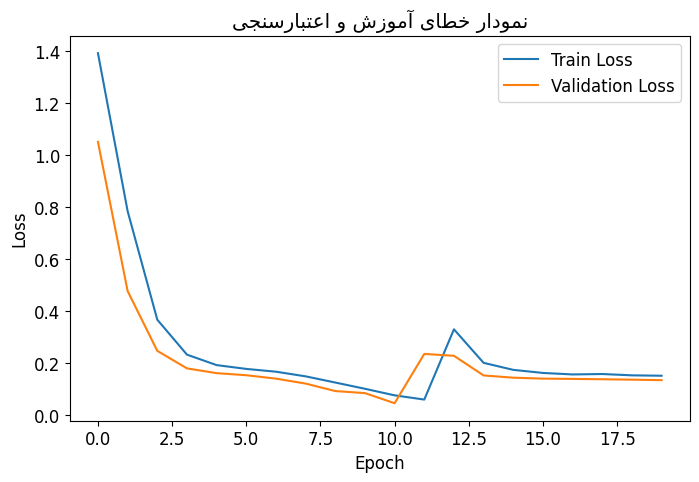

In [16]:
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title(fa_text('نمودار خطای آموزش و اعتبارسنجی'))
plt.legend()
plt.show()

<h4 dir=rtl align=right style="line-height:200%;font-family:vazir;color:#0099cc">
<font face="vazirmatn" color="#0099cc">
ارزیابی و نمایش نتایج مدل
</font>
</h4>
<p dir=rtl style="direction: rtl; text-align: justify; line-height:200%; font-family:vazir; font-size:medium">
<font face="vazirmatn" size=3>
در این بخش، مدل آموزش‌دیده را روی چند نمونه از داده‌های اعتبارسنجی آزمایش می‌کنیم و نتایج را به صورت تصویری نمایش می‌دهیم. برای هر نمونه، تصویر ورودی، ماسک واقعی (برچسب پیکسل‌ها) و ماسک پیش‌بینی‌شده توسط مدل را کنار هم می‌بینیم. این کار به ما کمک می‌کند کیفیت مدل را به صورت بصری ارزیابی کنیم و نقاط قوت و ضعف آن را بهتر بشناسیم.
</font>
</p>

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 680ms/step


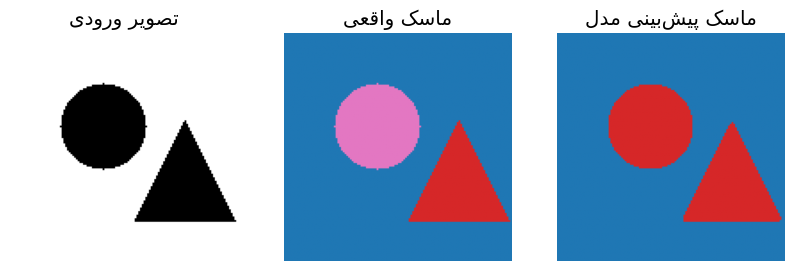

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step


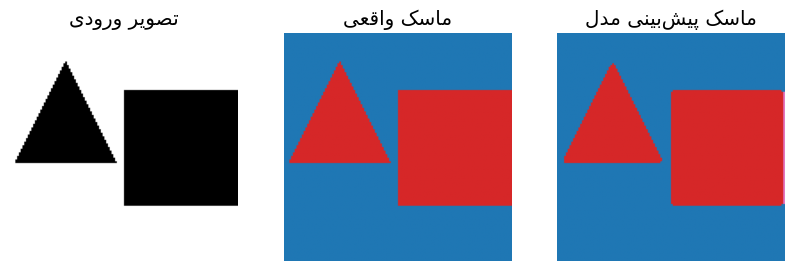

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step


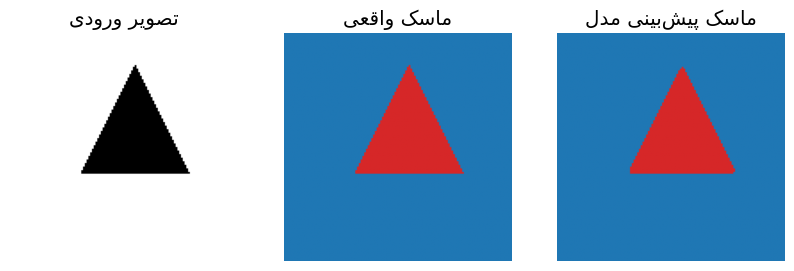

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step


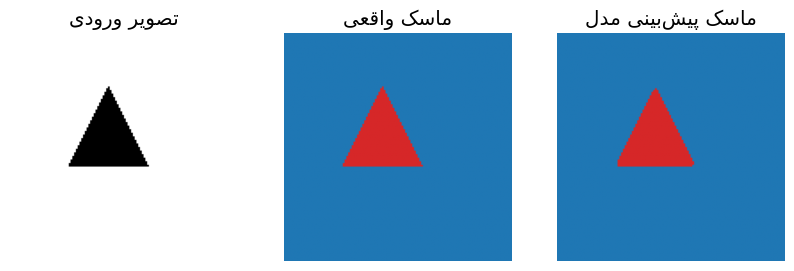

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step


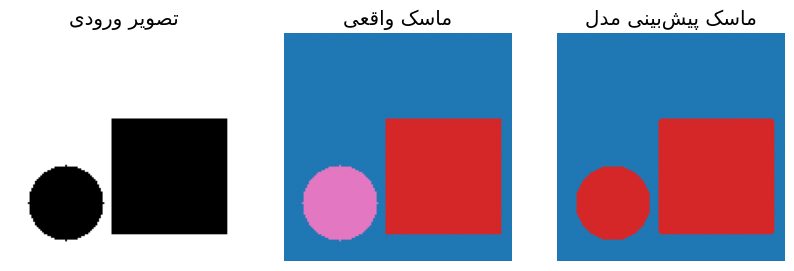

In [17]:
n_show = 5
for i in range(n_show):
    idx = np.random.randint(0, X_val.shape[0])
    img = X_val[idx]
    true_mask = Y_val[idx]
    pred_mask = model.predict(img[np.newaxis, ...])
    pred_mask = np.argmax(pred_mask[0], axis=-1)
    plt.figure(figsize=(10,3))
    plt.subplot(1,3,1)
    plt.imshow(img, cmap='gray')
    plt.title(fa_text('تصویر ورودی'))
    plt.axis('off')
    plt.subplot(1,3,2)
    plt.imshow(true_mask, cmap='tab10', vmin=0, vmax=3)
    plt.title(fa_text('ماسک واقعی'))
    plt.axis('off')
    plt.subplot(1,3,3)
    plt.imshow(pred_mask, cmap='tab10', vmin=0, vmax=3)
    plt.title(fa_text('ماسک پیش‌بینی مدل'))
    plt.axis('off')
    plt.show()